--- 統計數據摘要 ---
        char_count  token_count
count  8550.000000  8550.000000
mean    223.590643   326.205380
std     115.431427   165.199963
min       2.000000     2.000000
25%     137.000000   199.000000
50%     204.000000   298.000000
75%     306.000000   446.000000
max    1367.000000  1039.000000


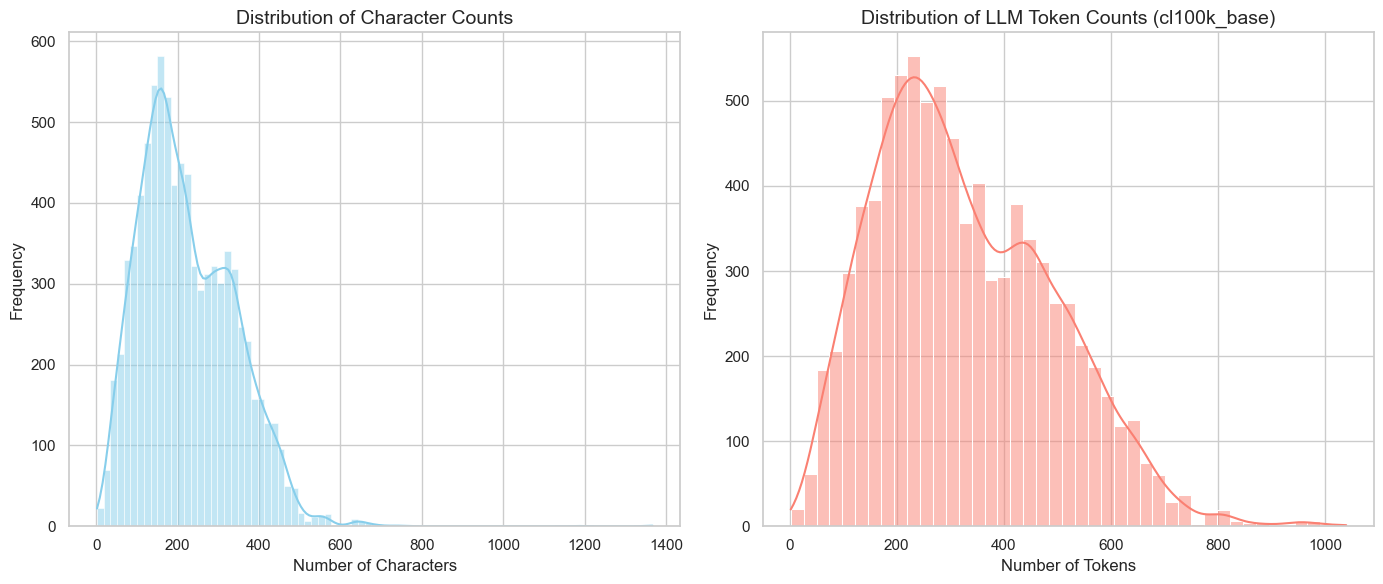

In [1]:
import pandas as pd
import tiktoken
import matplotlib.pyplot as plt
import seaborn as sns

# 設定路徑
file_path = "../data/all.xlsx"

try:
    # 1. 讀取 Excel 檔案
    df = pd.read_excel(file_path)
    
    # 確保 Article 欄位沒有空值
    df['Article'] = df['Article'].fillna("").astype(str)

    # 2. 計算字元分布 (Character Count)
    # 包含中文字、英文字母、空格與標點符號
    df['char_count'] = df['Article'].apply(len)

    # 3. 計算 LLM Token 分布
    # 使用 cl100k_base 編碼（適用於 GPT-4, GPT-3.5-turbo）
    encoding = tiktoken.get_encoding("cl100k_base")

    def get_token_count(text):
        return len(encoding.encode(text))

    df['token_count'] = df['Article'].apply(get_token_count)

    # 4. 計算統計數據
    summary_stats = df[['char_count', 'token_count']].describe()
    print("--- 統計數據摘要 ---")
    print(summary_stats)

    # 5. 繪製分布圖
    sns.set(style="whitegrid")
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    # 字元分布直方圖
    sns.histplot(df['char_count'], kde=True, ax=axes[0], color='skyblue')
    axes[0].set_title('Distribution of Character Counts', fontsize=14)
    axes[0].set_xlabel('Number of Characters')
    axes[0].set_ylabel('Frequency')

    # Token 分布直方圖
    sns.histplot(df['token_count'], kde=True, ax=axes[1], color='salmon')
    axes[1].set_title('Distribution of LLM Token Counts (cl100k_base)', fontsize=14)
    axes[1].set_xlabel('Number of Tokens')
    axes[1].set_ylabel('Frequency')

    plt.tight_layout()
    plt.show()

    # 可選：將計算結果存回新的 Excel
    # df.to_excel("article_analysis_results.xlsx", index=False)

except FileNotFoundError:
    print(f"錯誤：找不到檔案 {file_path}")
except Exception as e:
    print(f"發生錯誤：{e}")